Future improvements-

1. Being able to detect if there is more than 1 planet in the lightcurve (run the BLS algorithm again after removing the first spike)
2. Being able to download and analyse data from all sectors.
3. Swapping BLS with TLS (transit least squares) algorithm. Potential to write a research paper comparing the efficiency of a PyTorch model running BLS vs TLS.

## 1. Data Proccessing

### 1.1 Downloading Target Data

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline

import lightkurve as lk

/Users/Vallabh/Desktop/ML/TESS_ML/.venv/lib/python3.12/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [3]:
# Search the database and download lightcure data for the target star
search_result = lk.search_lightcurve("Pi Mensae", mission = "TESS", sector = 1)
search_result

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 01,2018,SPOC,120,261136679,0.0
1,TESS Sector 01,2018,TESS-SPOC,1800,261136679,0.0
2,TESS Sector 01,2018,QLP,1800,261136679,0.0
3,TESS Sector 01,2018,GSFC-ELEANOR-LITE,1800,261136679,0.0
4,TESS Sector 01,2018,TARS,1800,261136679,0.0
5,TESS Sector 01,2018,TASOC,120,261136679,0.0
6,TESS Sector 01,2018,TASOC,1800,261136679,0.0
7,TESS Sector 01,2018,TASOC,1800,261136679,0.0


From the list of observations, the required observations are the ones with _author = SPOC_

In this case, only the first observation matches this requirement.

Download raw data from the first observation and display it before processing it and cleaning the data-

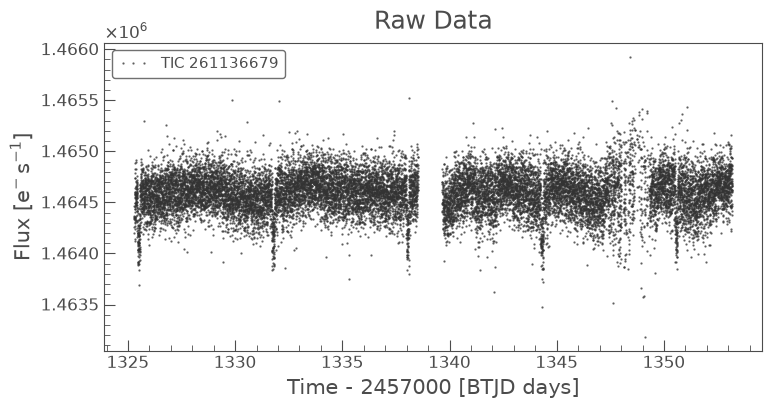

In [ ]:
lc_0 = search_result[0].download()

""" Arguments for lc.plot() function-
linewidth = 0 : Remove the default representation of the lightcurve using lines
marker = '.' : Set the marker to '.' to make visualization easier
markersize = 1.3 : Reduce the marker size for easier visualizationn
alpha = 0.7 : Measure of transparency of the marker used in the lightcurve
"""

# Plot raw lightcurve data
title = "Raw Data"
lc_0.plot(title = title, linewidth = 0, marker = '.', markersize = 1.3, alpha = 0.7);

### 1.2 Cleaning the data

Next, for cleaning the lightcurve data, the following two in-built lightkurve functions will be used-

1. __lc.remove_nans()__ : Removes all the data points which are listed as NaN (Not a Number), which includes time, flux and flux error data points. TESS data pipelines usually insert NaNs during data gaps (TESS pauses scientific observations and downlinks the data to ground stations on Earth every 13.7 days, which causes the data gap that can be seen in the middle of the lightcurve), instrument transitions (there are usually _systemic errors_ around the 6 day and 18.5 day mark) and other random events such as a cosmic ray flag event.
   
2. __lc.flatten()__ : This method applies a high-pass filter to the data to remove long term trends such as _stellar variability_, _stellar rotation_, _instrument drift_ and others which cause the baseline flux to increase and decrease over a period of days or even weeks. The flatten function normalizes the baseline flux to a value of 1.0

**IMPORTANT FIX : _lc.flatten()_ uses a Savitzky-Golay (SavGol) filter, which uses a window of data points, usually of length 101. This may be too short for some transits, and can result in the transit data being LOST. To fix this issue, set the hyperparameter _window_length_ to a large value (such as 901) which will preserve the transit data, but remove the long-term stellar trends.**

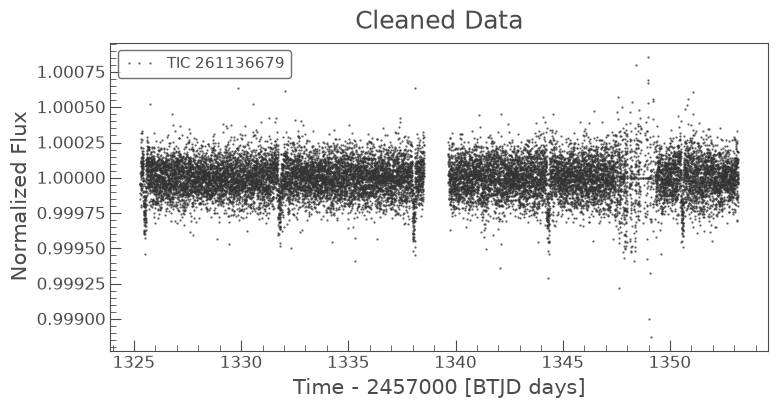

In [5]:
lc_0_cleaned = lc_0.remove_nans().flatten(window_length = 901)

title = "Cleaned Data"
lc_0_cleaned.plot(title = title, linewidth = 0, marker = '.', markersize = 1.3, alpha = 0.7);

### 1.3 Finding the Orbital Period

To detect potential transit events, BLS (Box Least Squares) algorithm is implemented. It is a highly specialised algorithm for astronomy, designed to be used on data having data points at baseline for the majority of observation time and seldom contain data points varying from baseline (transit data points).

Working of BLS algorithm is as follows - 

1) The algorithm guesses an orbital period, starting with _minimum_period_ (hyperparameter) upto _maximum_period_ (hyperparameter)
2) It temporarily phase-folds the data based on the orbital period guess it made
3) A mathematical box is drawn over the phase-folded data
4) The algorithm then runs a Least Squares on the drawn box shape and the phase-folded data
5) Based on how close the phase-folded data is to the drawn box, it assigns a power score to that orbital period. A higher power score means the data fit the box better causing less error, making the orbital period more likely to be correct.
6) Repeats this process for all orbital periods in the range [_minimum_period_, _maximum_period_]

After the algorithm has finished running, the orbital period with the highest power score (the largest spike that can be seen in the BLS Periodogram) is selected as the most likely orbital period for any potential exoplanet candidates in the lightcurve data.

NOTE : There is another better suited algorithm called TLS (Transit Least Squares), which has higher accuracy in detecting transits. It acheieves this by taking into account the 'Limb Darkening' phenomenon that occurs when a transit occurs, which causes a U-shaped dip instead of a box shaped dip. The reason for not implementing TLS in this project is the high computational cost of TLS. For large datasets (tens of thousands of stars), training a model using BLS is much faster than training it on TLS. Furthermore, the accuracy provided by TLS is not really required for the scope of this project, since the convolutional neural network does the work of classifying transits accurately.

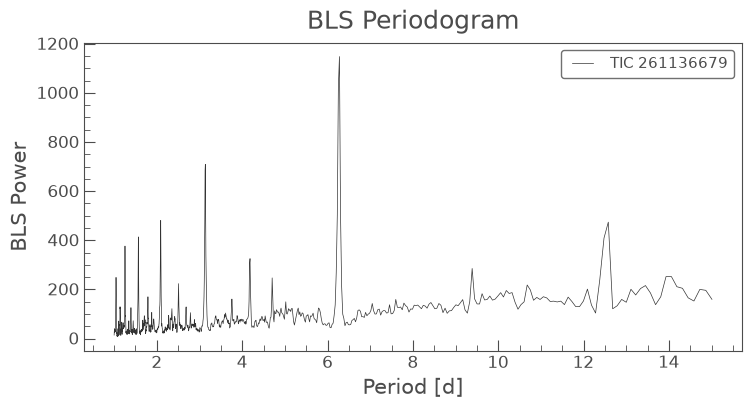

In [6]:
periodogram = lc_0_cleaned.to_periodogram(method = "bls", minimum_period = 1, maximum_period = 15)
periodogram.plot(title = "BLS Periodogram");

In [ ]:
# Extracting the most likely orbital period found by BLS
best_period = periodogram.period_at_max_power

# Extracting the first detected epoch of a transit by BLS
first_epoch = periodogram.transit_time_at_max_power

print(best_period)
print(first_epoch.value)

6.278663461778693 d
1325.4869604950604


### 1.4 Phase-Folding Target Data

Phase-Folding the target lightcurve data is a crucial step in finding candidate exoplanet transits. It filters out the noise and gives a strong and deep transit signal, if one exists.

The data is folded on top of itself, with the length of the fold being the calulated orbital period data by BLS which results in all the transit signals being stacked on top of each other giving a single, definitive signal.

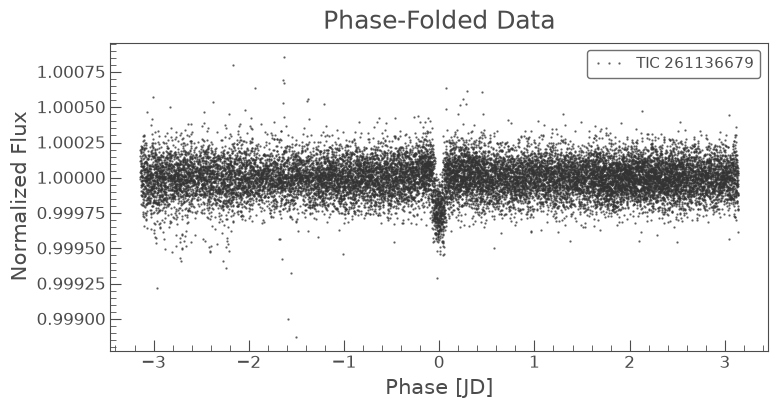

In [8]:
lc_0_folded = lc_0_cleaned.fold(period = best_period, epoch_time = first_epoch)

title = "Phase-Folded Data"
lc_0_folded.plot(title = title, linewidth = 0, marker = '.', markersize = 1.3, alpha = 0.7);

### 1.5 Extracting Raw Numbers from Lightcurve data for PyTorch

In [9]:
time_array = lc_0_folded.time.value
flux_array = lc_0_folded.flux.value

time_array, flux_array

(array([-3.1391158 , -3.13872114, -3.13832345, ...,  3.1381588 ,
         3.13855346,  3.13912637], shape=(18264,)),
 MaskedNDArray([0.99998945, 1.00015122, 1.00000828, ..., 1.00004643,
                1.00006713, 1.00003755], shape=(18264,)))